Импорты, загрузка датасета

In [ ]:
import numpy as np
import pandas as pd

import math

from sklearn.preprocessing import OneHotEncoder
import matplotlib
import matplotlib.image as img
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

import os

import kagglehub

path = kagglehub.dataset_download("mahdimashayekhi/social-media-vs-productivity")
file = os.path.join(path,"social_media_vs_productivity.csv")

100%|██████████| 2.26M/2.26M [00:00<00:00, 131MB/s]

Extracting files...


In [ ]:
matplotlib.rcParams.update({'font.size': 12})

In [ ]:
df = pd.read_csv(file)

df.head()

,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,56,Male,Unemployed,4.180940,Facebook,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,8,False,False,4,11,21.927072,6.336688
1,46,Male,Health,3.249603,Twitter,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,7,True,True,2,25,0.000000,3.412427
2,32,Male,Finance,NaN,Twitter,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,0,True,False,3,17,10.322044,2.474944
3,60,Female,Unemployed,NaN,Facebook,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,1,False,False,0,4,23.876616,1.733670
4,25,Male,IT,NaN,Telegram,66,6.214096,8.868753,NaN,7.0,5.405706,1.876254,1,False,True,1,30,10.653519,9.693060


Вывод информации о датасете

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  object 
 2   job_type                        30000 non-null  object 
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  object 
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              

In [ ]:
df.describe()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
count,30000.000000,27235.000000,30000.000000,30000.000000,28386.000000,27635.000000,28096.000000,27402.000000,27789.000000,30000.000000,30000.000000,30000.000000,30000.000000,27270.000000
mean,41.486867,3.113418,59.958767,6.990792,5.510488,4.951805,5.514059,6.500247,1.025568,4.992200,1.999300,15.557067,10.360655,4.964901
std,13.835221,2.074813,7.723772,1.997736,2.023470,1.883378,2.866344,1.464004,0.653355,3.173737,1.410047,9.252956,7.280415,2.121194
min,18.000000,0.000000,30.000000,0.000000,2.000252,0.296812,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,1.639566,55.000000,5.643771,3.757861,3.373284,3.000000,5.493536,0.528490,2.000000,1.000000,8.000000,4.541872,3.363580
50%,41.000000,3.025913,60.000000,6.990641,5.525005,4.951742,6.000000,6.498340,1.006159,5.000000,2.000000,16.000000,10.013677,4.951049
75%,53.000000,4.368917,65.000000,8.354725,7.265776,6.526342,8.000000,7.504143,1.477221,8.000000,3.000000,24.000000,15.300809,6.581323
max,65.000000,17.973256,90.000000,12.000000,8.999376,9.846258,10.000000,10.000000,3.000000,10.000000,10.000000,31.000000,40.964769,10.000000


In [ ]:
df.describe(include='object')

,gender,job_type,social_platform_preference
count,30000,30000,30000
unique,3,6,5
top,Male,Education,TikTok
freq,14452,5055,6096


# 1. Распределение целевой переменной

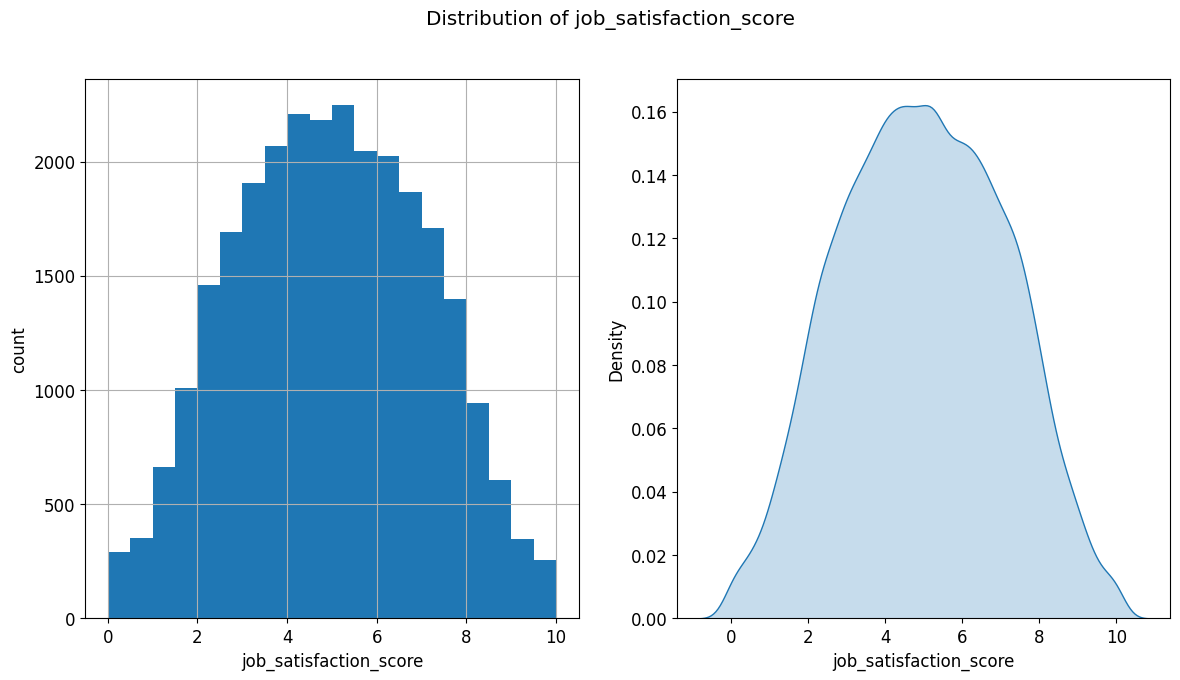

In [ ]:
plt.figure(figsize = (14, 7))

plt.subplot(121)
df['job_satisfaction_score'].hist(density=False, bins=20)
plt.ylabel('count')
plt.xlabel('job_satisfaction_score')

plt.subplot(122)
sns.kdeplot(df['job_satisfaction_score'], shade=True, legend=False)
plt.xlabel('job_satisfaction_score')

plt.suptitle('Distribution of job_satisfaction_score')
plt.show()

# 2. Анализ признаков

**2.1 Работа с пропусками**

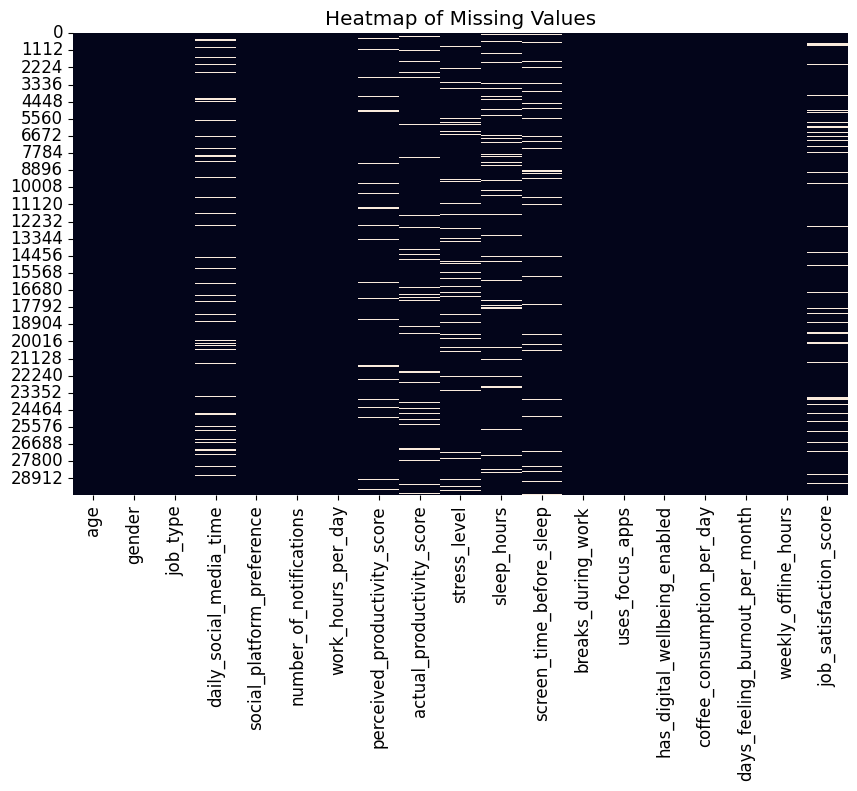

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="rocket")
plt.title("Heatmap of Missing Values")
plt.show()

In [ ]:
print('\nКоличество пропусков по столбцам:')
print(df.isna().sum())


Количество пропусков по столбцам:
age                                  0
gender                               0
job_type                             0
daily_social_media_time           2765
social_platform_preference           0
number_of_notifications              0
work_hours_per_day                   0
perceived_productivity_score      1614
actual_productivity_score         2365
stress_level                      1904
sleep_hours                       2598
screen_time_before_sleep          2211
breaks_during_work                   0
uses_focus_apps                      0
has_digital_wellbeing_enabled        0
coffee_consumption_per_day           0
days_feeling_burnout_per_month       0
weekly_offline_hours                 0
job_satisfaction_score            2730
dtype: int64


In [ ]:
columns_to_impute = [
    'daily_social_media_time',
    'perceived_productivity_score',
    'actual_productivity_score',
    'stress_level',
    'sleep_hours',
    'screen_time_before_sleep',
    'job_satisfaction_score'
]

for col in columns_to_impute:
    median_val = df[col].median()
    df[col].fillna(median_val, inplace=True)

In [ ]:
print('\nКоличество пропусков по столбцам после заполнения:')
print(df.isna().sum())


Количество пропусков по столбцам после заполнения:
age                               0
gender                            0
job_type                          0
daily_social_media_time           0
social_platform_preference        0
number_of_notifications           0
work_hours_per_day                0
perceived_productivity_score      0
actual_productivity_score         0
stress_level                      0
sleep_hours                       0
screen_time_before_sleep          0
breaks_during_work                0
uses_focus_apps                   0
has_digital_wellbeing_enabled     0
coffee_consumption_per_day        0
days_feeling_burnout_per_month    0
weekly_offline_hours              0
job_satisfaction_score            0
dtype: int64


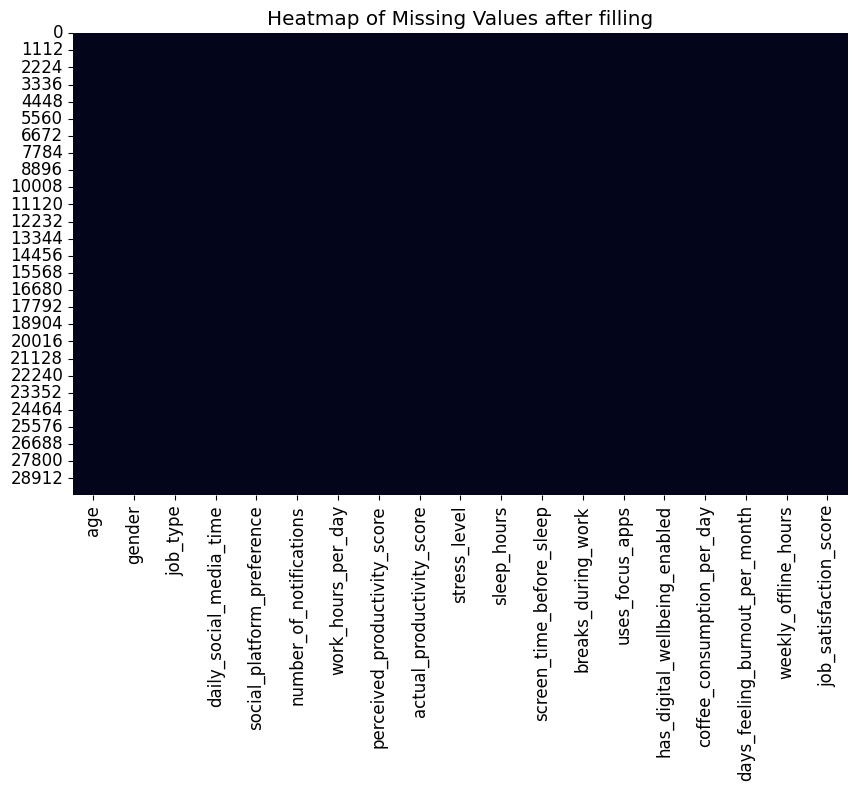

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="rocket")
plt.title("Heatmap of Missing Values after filling")
plt.show()

**2.2 Количественные признаки**

In [ ]:
df_num_features = df.select_dtypes(include=['float64', 'int64'])
# df_num_features.drop('job_satisfaction_score', axis=1, inplace=True)
df_num_features.head()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,56,4.180940,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,8,4,11,21.927072,6.336688
1,46,3.249603,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,7,2,25,0.000000,3.412427
2,32,3.025913,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,0,3,17,10.322044,2.474944
3,60,3.025913,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,1,0,4,23.876616,1.733670
4,25,3.025913,66,6.214096,8.868753,4.951742,7.0,5.405706,1.876254,1,1,30,10.653519,9.693060


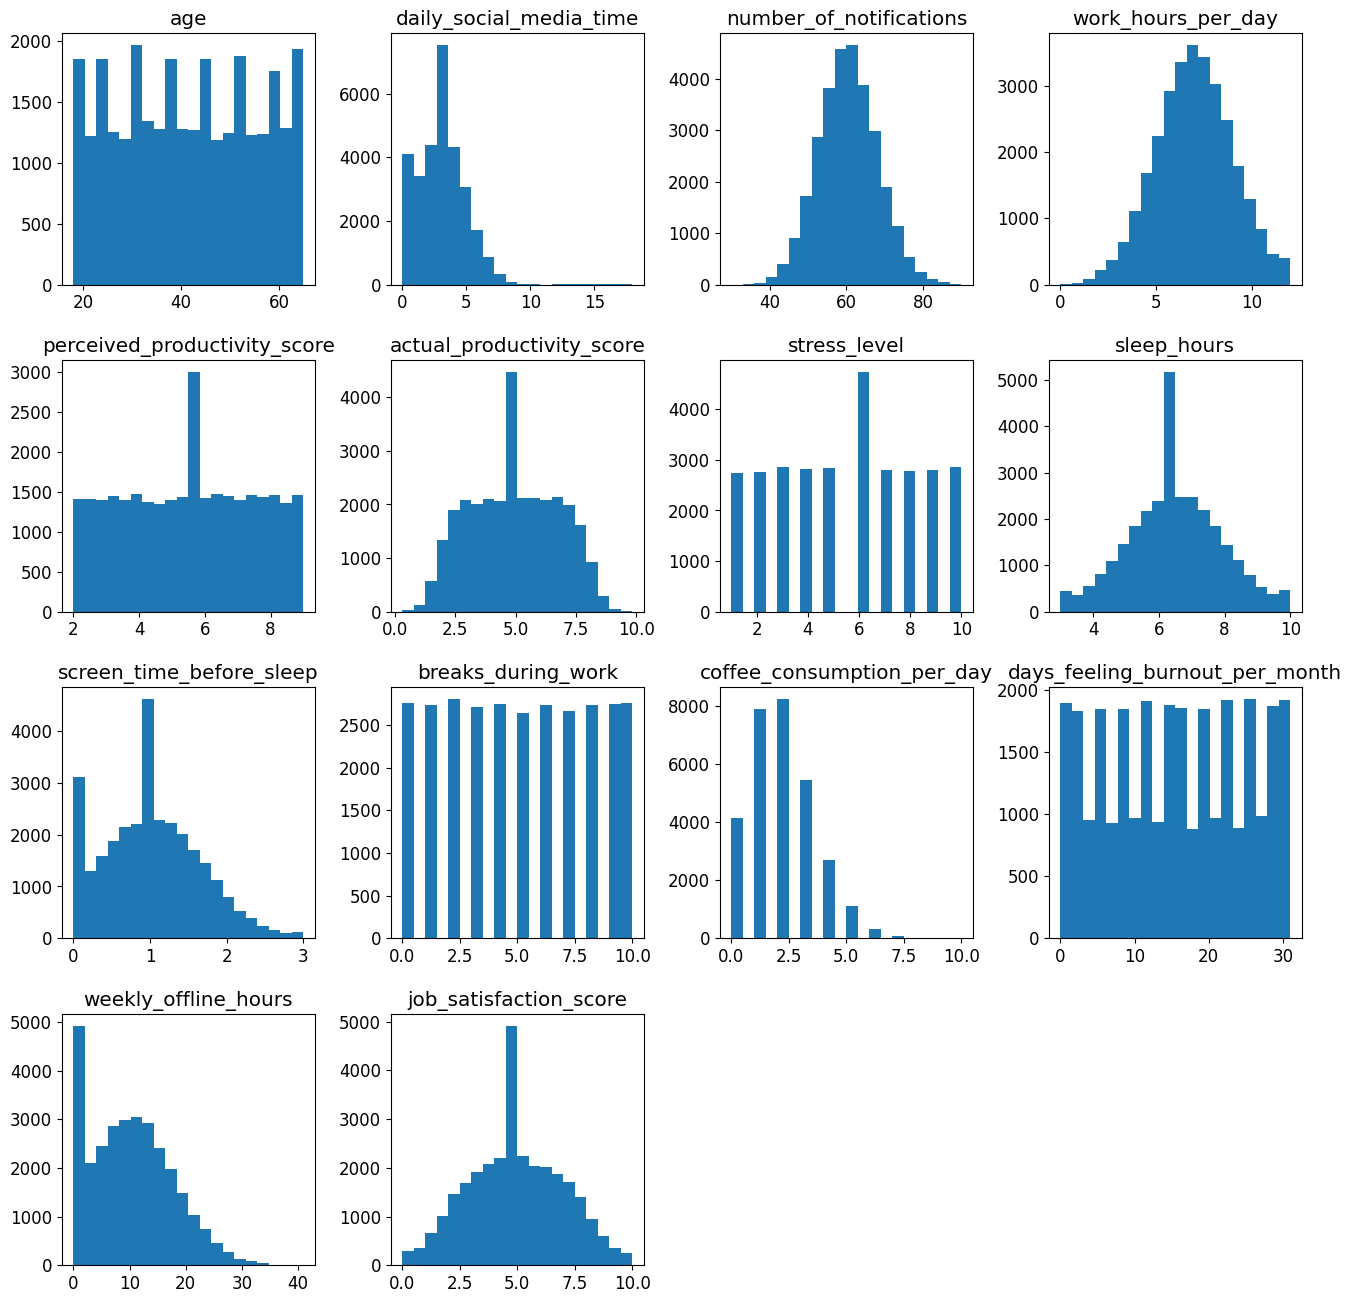

In [ ]:
df_num_features.hist(figsize=(16, 16), bins=20, grid=False);

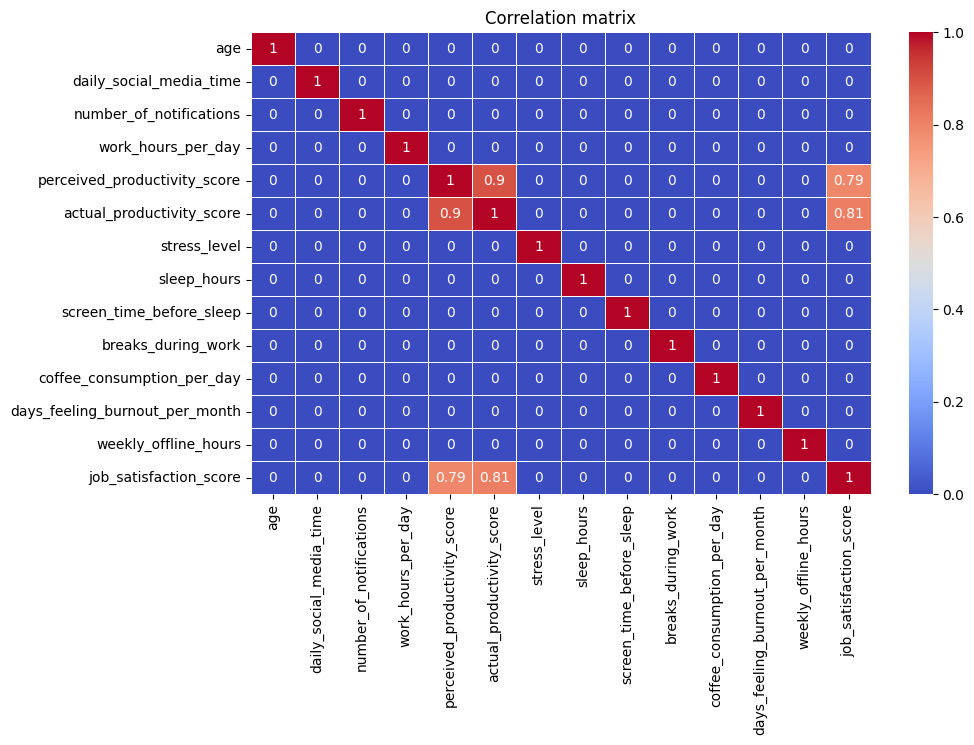

In [ ]:
plt.figure(figsize=(10, 6))

matplotlib.rcParams.update({'font.size': 10})

corr_matrix = df_num_features.corr()
corr_matrix = np.round(corr_matrix, 2)
corr_matrix[np.abs(corr_matrix) < 0.3] = 0

sns.heatmap(corr_matrix, annot=True, linewidths=.5, cmap='coolwarm')

plt.title('Correlation matrix')
plt.show()

**Поиск аномальных значений**

*  С помощью средств визуализации (боксплоты)


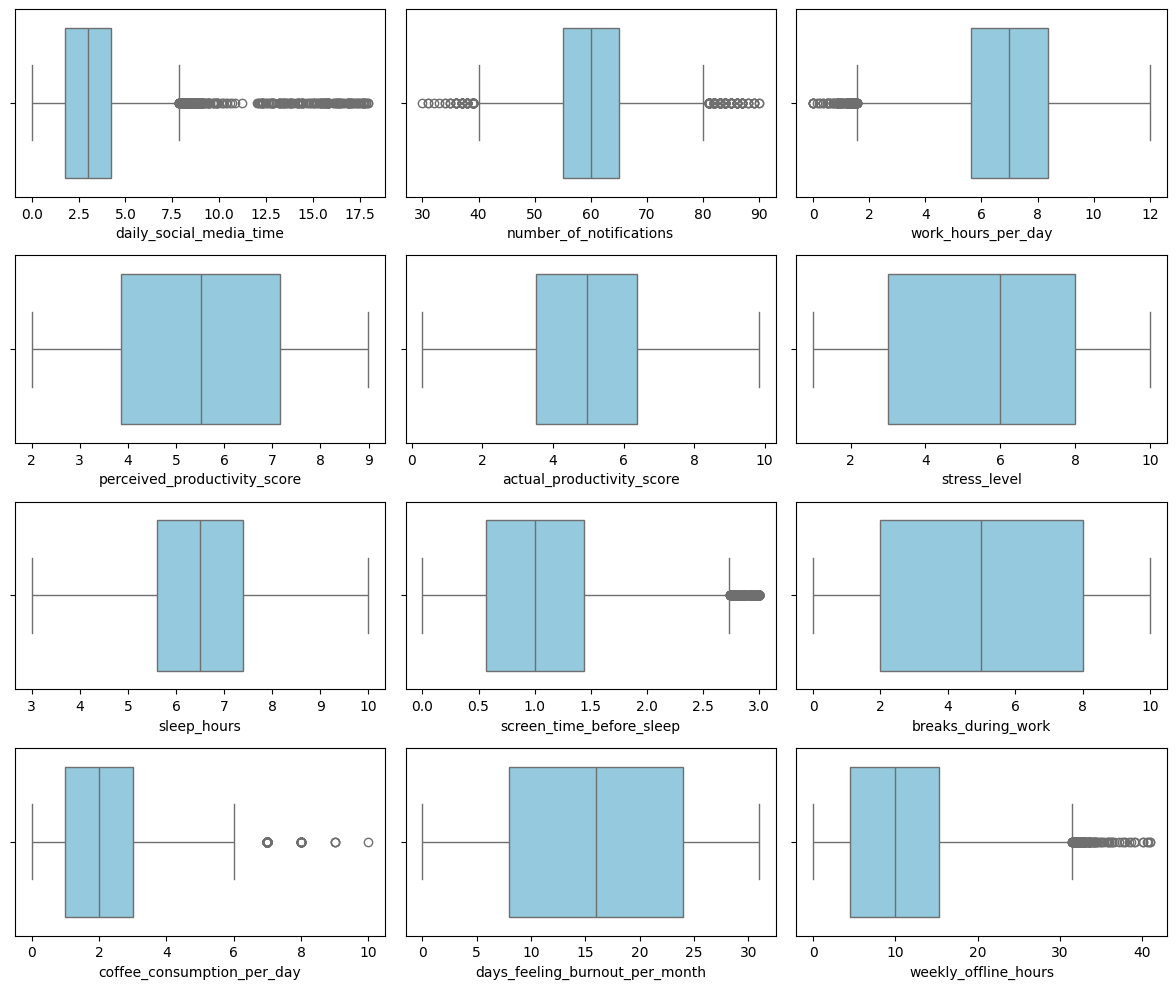

In [ ]:
df_num_features.drop('age', axis=1, inplace=True)
df_num_features.drop('job_satisfaction_score', axis=1, inplace=True)

plt.figure(figsize=(12, 10))
for i, col in enumerate(df_num_features):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x=df[col], color='skyblue')

plt.tight_layout()
plt.show()


*  С помощью статистических методов

In [ ]:
df_clean = df.copy()
print("Интерквартильный размах (IQR):")
for col in df_num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    num_outliers = outliers.shape[0]
    percentage = (num_outliers / df.shape[0]) * 100

    if num_outliers > 0:
        print(f"{col}: {num_outliers} выбросов ({percentage:.2f}%)")
    else:
        print(f"{col}: Выбросов не обнаружено.")

Интерквартильный размах (IQR):
daily_social_media_time: 348 выбросов (1.16%)
number_of_notifications: 261 выбросов (0.87%)
work_hours_per_day: 97 выбросов (0.32%)
perceived_productivity_score: Выбросов не обнаружено.
actual_productivity_score: Выбросов не обнаружено.
stress_level: Выбросов не обнаружено.
sleep_hours: Выбросов не обнаружено.
screen_time_before_sleep: 198 выбросов (0.66%)
breaks_during_work: Выбросов не обнаружено.
coffee_consumption_per_day: 127 выбросов (0.42%)
days_feeling_burnout_per_month: Выбросов не обнаружено.
weekly_offline_hours: 116 выбросов (0.39%)


Избавление от выбросов с помощью клиппинга:

In [ ]:
for col in df_num_features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)

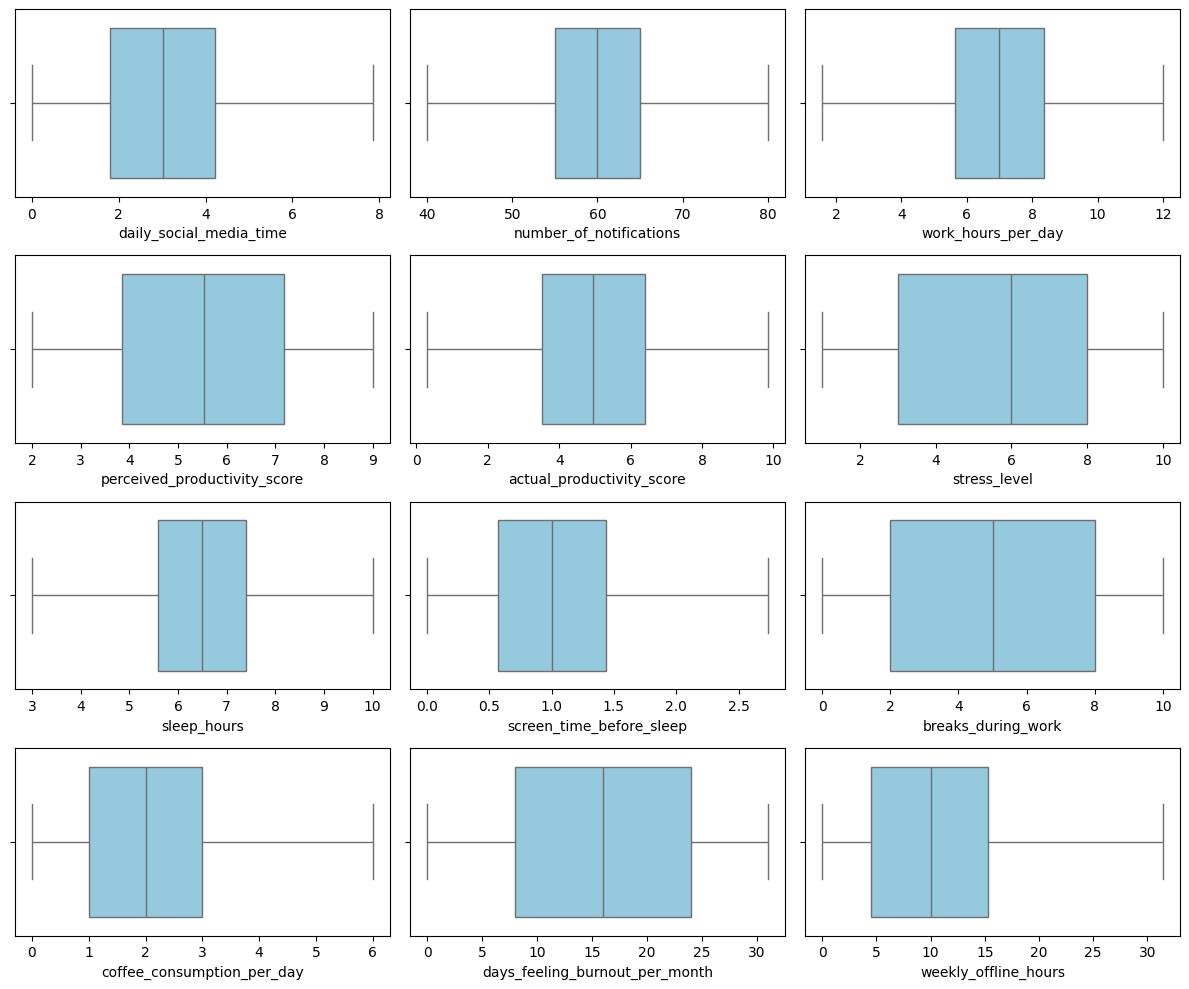

In [ ]:
plt.figure(figsize=(12, 10))
for i, col in enumerate(df_num_features):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x=df_clean[col], color='skyblue')

plt.tight_layout()
plt.show()

**2.3 Кодирование категориальных признаков**

*  бинаризация признака "gender"

In [ ]:
df_encoded = df_clean.copy()

df_encoded ['gender'] = [1 if i == 'Female' else 0 for i in df_encoded ['gender']]


In [ ]:
df_encoded['uses_focus_apps'] = df_encoded['uses_focus_apps'].astype(int)
df_encoded['has_digital_wellbeing_enabled'] =df_encoded['has_digital_wellbeing_enabled'].astype(int)

*  OHE-кодирование

In [ ]:
df_encoded = pd.get_dummies(df_encoded, dtype=int, columns=['job_type', 'social_platform_preference'], prefix=['job_type', 'social_platform_preference'], drop_first=True)
df_encoded.head()

,age,gender,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,...,job_satisfaction_score,job_type_Finance,job_type_Health,job_type_IT,job_type_Student,job_type_Unemployed,social_platform_preference_Instagram,social_platform_preference_Telegram,social_platform_preference_TikTok,social_platform_preference_Twitter
0,56,0,4.180940,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,...,6.336688,0,0,0,0,1,0,0,0,0
1,46,0,3.249603,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,...,3.412427,0,1,0,0,0,0,0,0,1
2,32,0,3.025913,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,...,2.474944,1,0,0,0,0,0,0,0,1
3,60,1,3.025913,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,...,1.733670,0,0,0,0,1,0,0,0,0
4,25,0,3.025913,66,6.214096,8.868753,4.951742,7.0,5.405706,1.876254,...,9.693060,0,0,1,0,0,0,1,0,0


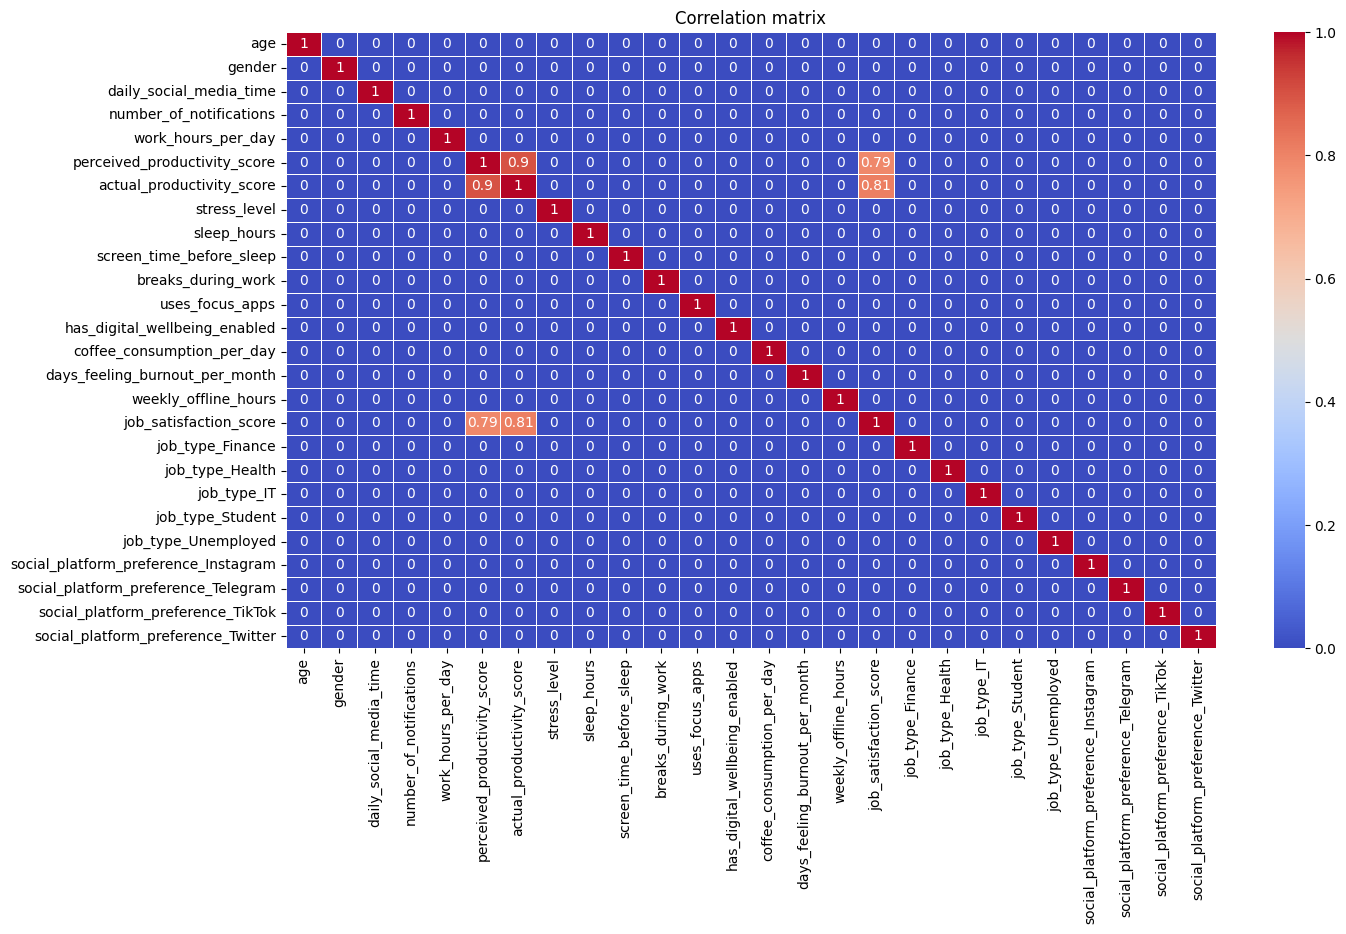

In [ ]:
plt.figure(figsize=(15, 8))

matplotlib.rcParams.update({'font.size': 10})

corr_matrix = df_encoded.corr()
corr_matrix = np.round(corr_matrix, 2)
corr_matrix[np.abs(corr_matrix) < 0.3] = 0

sns.heatmap(corr_matrix, annot=True, linewidths=.5, cmap='coolwarm')

plt.title('Correlation matrix')
plt.show()

In [ ]:
correlation_with_target = df_encoded.corr(numeric_only=True)['job_satisfaction_score'].sort_values(ascending=False)
print(correlation_with_target)

job_satisfaction_score                  1.000000
actual_productivity_score               0.809289
perceived_productivity_score            0.791144
job_type_IT                             0.016105
age                                     0.013436
social_platform_preference_TikTok       0.010129
screen_time_before_sleep                0.005021
social_platform_preference_Telegram     0.003850
uses_focus_apps                         0.003221
coffee_consumption_per_day              0.002149
social_platform_preference_Twitter      0.000970
job_type_Health                         0.000655
stress_level                           -0.000580
gender                                 -0.001466
work_hours_per_day                     -0.002071
job_type_Finance                       -0.002129
has_digital_wellbeing_enabled          -0.002584
breaks_during_work                     -0.003124
daily_social_media_time                -0.003342
social_platform_preference_Instagram   -0.003755
job_type_Unemployed 

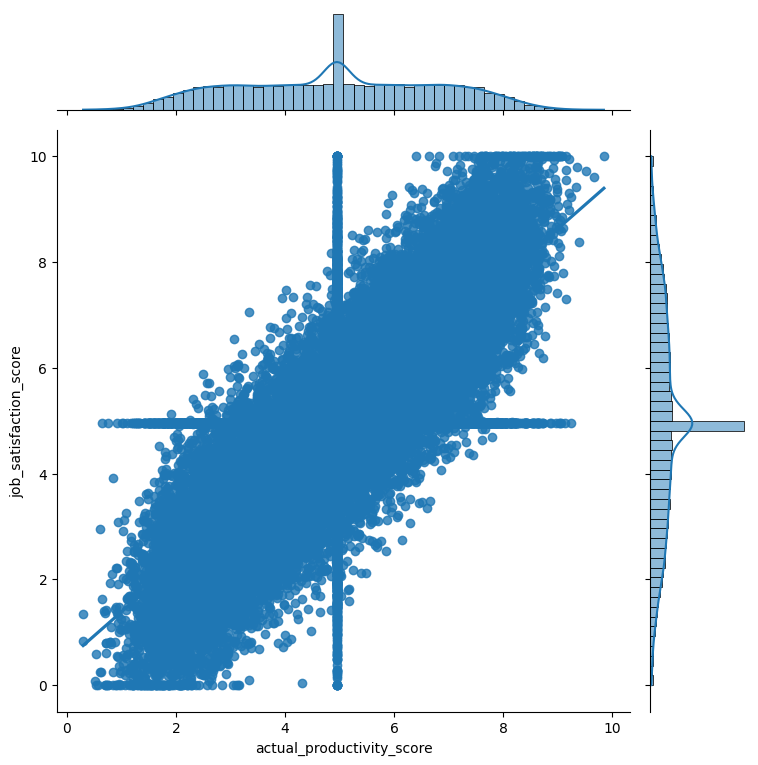

In [ ]:
grid = sns.jointplot(x=df_encoded['actual_productivity_score'], y=df_encoded['job_satisfaction_score'], kind='reg')
grid.fig.set_figwidth(8)
grid.fig.set_figheight(8)

plt.show()

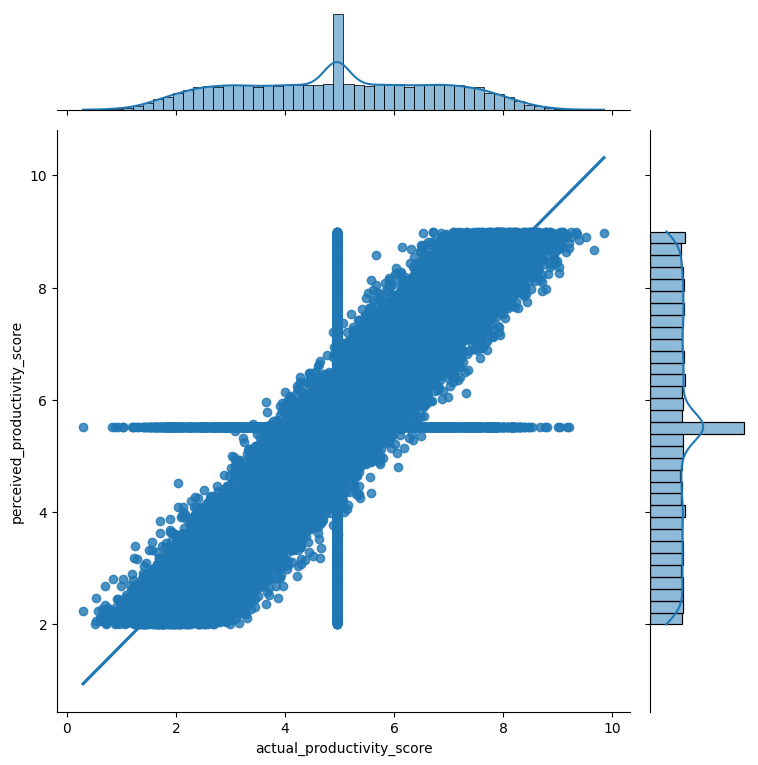

In [ ]:
grid = sns.jointplot(x=df_encoded['actual_productivity_score'], y=df_encoded['perceived_productivity_score'], kind='reg')
grid.fig.set_figwidth(8)
grid.fig.set_figheight(8)

plt.show()

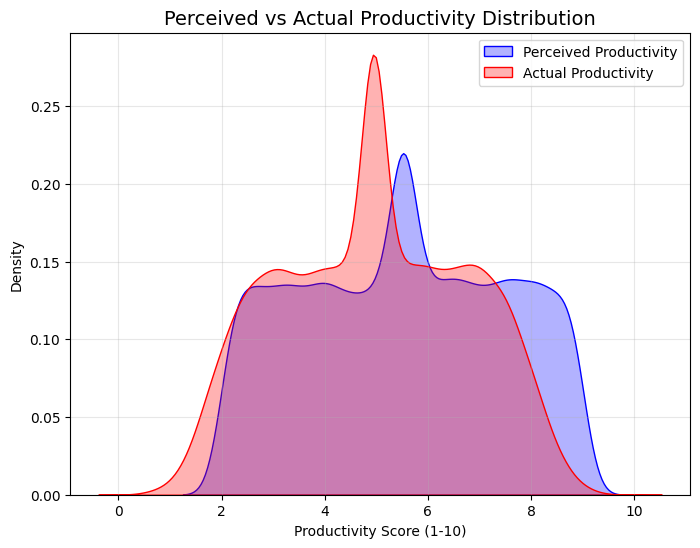

Mean Perceived Score: 5.51
Mean Actual Score:    4.95
Overestimation Gap:   0.56


In [ ]:
plt.figure(figsize=(8, 6))
sns.kdeplot(data=df, x='perceived_productivity_score', label='Perceived Productivity', fill=True, color='blue', alpha=0.3)
sns.kdeplot(data=df, x='actual_productivity_score', label='Actual Productivity', fill=True, color='red', alpha=0.3)

plt.title('Perceived vs Actual Productivity Distribution', fontsize=14)
plt.xlabel('Productivity Score (1-10)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

perceived_mean = df_encoded['perceived_productivity_score'].mean()
actual_mean = df_encoded['actual_productivity_score'].mean()
gap = perceived_mean - actual_mean

print(f"Mean Perceived Score: {perceived_mean:.2f}")
print(f"Mean Actual Score:    {actual_mean:.2f}")
print(f"Overestimation Gap:   {gap:.2f}")

**2.4 Генерация новых признаков:**

In [ ]:
df_encoded['offline_ratio'] = df_encoded['weekly_offline_hours'] / (7*24) * 100
df_encoded['coffee_stress_interaction'] = df_encoded['coffee_consumption_per_day'] * df_encoded['stress_level']
df_encoded['productivity_gap'] =  df_encoded['perceived_productivity_score'] - df_encoded['actual_productivity_score']
df_encoded['high_screen_before_sleep'] = (df_encoded['screen_time_before_sleep'] > df_encoded['screen_time_before_sleep'].median()).astype(int)

In [ ]:
df_encoded.head()

,age,gender,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,...,job_type_Student,job_type_Unemployed,social_platform_preference_Instagram,social_platform_preference_Telegram,social_platform_preference_TikTok,social_platform_preference_Twitter,offline_ratio,coffee_stress_interaction,productivity_gap,high_screen_before_sleep
0,56,0,4.180940,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,...,0,1,0,0,0,0,13.051829,16.0,0.748909,0
1,46,0,3.249603,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,...,0,0,0,0,0,1,0.000000,14.0,-0.101725,0
2,32,0,3.025913,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,...,0,0,0,0,0,1,6.144074,12.0,0.387709,0
3,60,1,3.025913,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,...,0,1,0,0,0,0,14.212271,0.0,1.141462,1
4,25,0,3.025913,66,6.214096,8.868753,4.951742,7.0,5.405706,1.876254,...,0,0,0,1,0,0,6.341380,7.0,3.917011,1


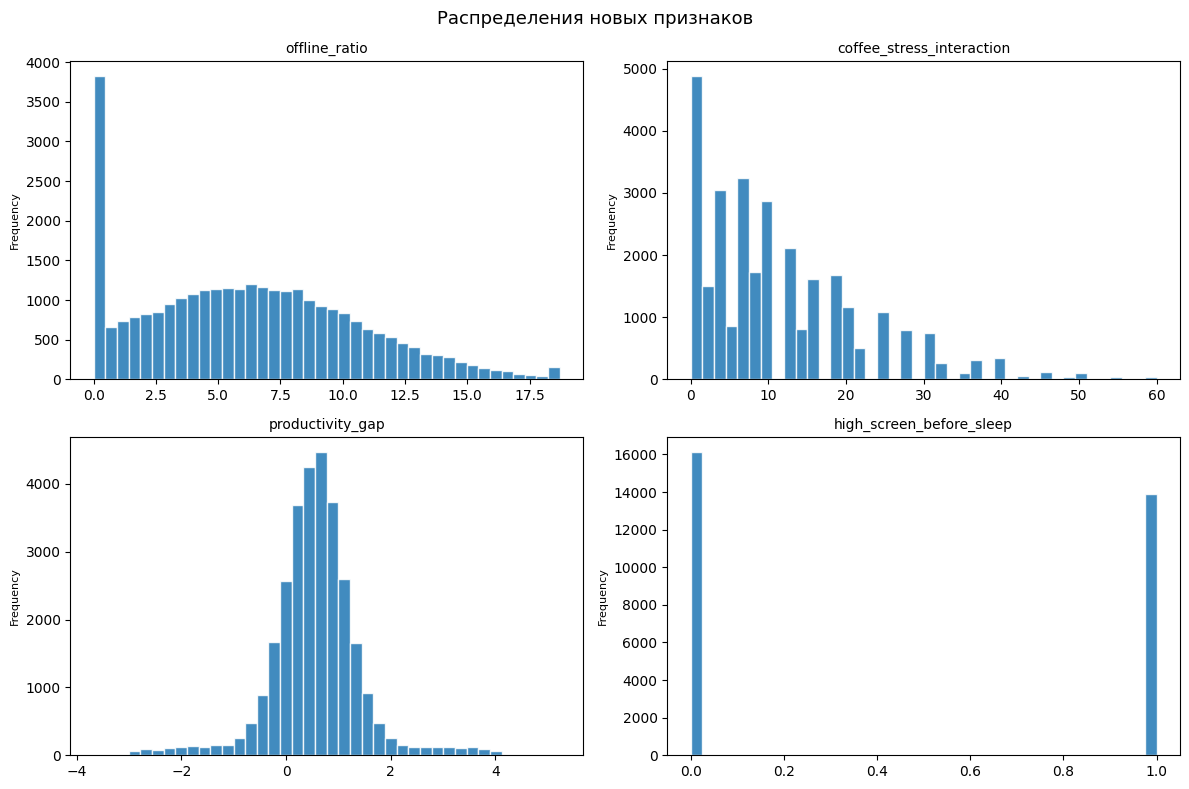

In [ ]:
new_features = [
    'offline_ratio', 'coffee_stress_interaction', 'productivity_gap',
    'high_screen_before_sleep']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, col in enumerate(new_features):
    axes[i].hist(df_encoded[col], bins=40,
                 alpha=0.85, edgecolor='white')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=8)

plt.suptitle('Распределения новых признаков', fontsize=13)
plt.tight_layout()
plt.show()

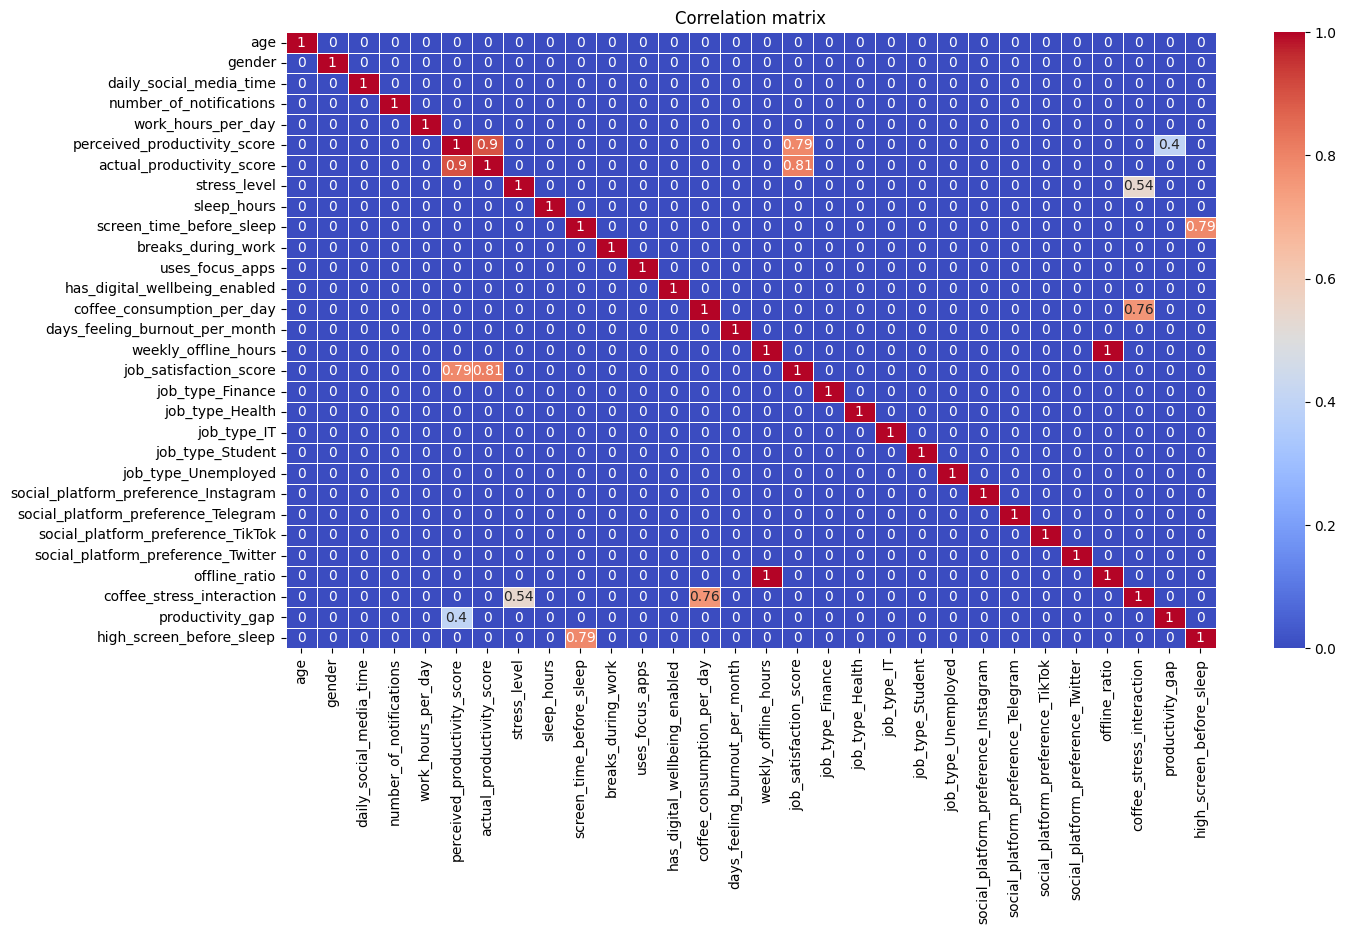

In [ ]:
plt.figure(figsize=(15, 8))

matplotlib.rcParams.update({'font.size': 10})

corr_matrix = df_encoded.corr()
corr_matrix = np.round(corr_matrix, 2)
corr_matrix[np.abs(corr_matrix) < 0.3] = 0

sns.heatmap(corr_matrix, annot=True, linewidths=.5, cmap='coolwarm')

plt.title('Correlation matrix')
plt.show()

# 3. Масштабирование

*   нормализация



In [ ]:
df_norm = df_encoded.copy()
mms = MinMaxScaler()
df_norm = pd.DataFrame(mms.fit_transform(df_norm), columns=df_encoded.columns, index=df_encoded.index)
df_norm.describe()

,age,gender,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,...,job_type_Student,job_type_Unemployed,social_platform_preference_Instagram,social_platform_preference_Telegram,social_platform_preference_TikTok,social_platform_preference_Twitter,offline_ratio,coffee_stress_interaction,productivity_gap,high_screen_before_sleep
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.499721,0.479000,0.390576,0.498667,0.519555,0.501637,0.487462,0.504989,0.500012,0.374064,...,0.167067,0.165267,0.200200,0.200433,0.203200,0.198800,0.329253,0.184207,0.475646,0.463133
std,0.294366,0.499567,0.230549,0.191192,0.191194,0.281219,0.189290,0.308491,0.199882,0.228831,...,0.373042,0.371427,0.400157,0.400331,0.402387,0.399104,0.230626,0.170474,0.095816,0.498647
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.255319,0.000000,0.228948,0.375000,0.390153,0.265512,0.336409,0.222222,0.371277,0.208241,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.144465,0.050000,0.429746,0.000000
50%,0.489362,0.000000,0.385358,0.500000,0.519378,0.503599,0.487455,0.555556,0.499763,0.367863,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.318509,0.133333,0.475758,0.000000
75%,0.744681,1.000000,0.537369,0.625000,0.650255,0.738351,0.638725,0.777778,0.628425,0.524945,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.486679,0.266667,0.520893,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


*   стандартизация

In [ ]:
df_std = df_encoded.copy()
scaler = StandardScaler()
df_std = pd.DataFrame(scaler.fit_transform(df_std), columns=df_encoded.columns, index=df_encoded.index)
df_std.describe().round(3)

,age,gender,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,...,job_type_Student,job_type_Unemployed,social_platform_preference_Instagram,social_platform_preference_Telegram,social_platform_preference_TikTok,social_platform_preference_Twitter,offline_ratio,coffee_stress_interaction,productivity_gap,high_screen_before_sleep
count,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,...,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000
mean,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,...,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.698,-0.959,-1.694,-2.608,-2.717,-1.784,-2.575,-1.637,-2.502,-1.635,...,-0.448,-0.445,-0.500,-0.501,-0.505,-0.498,-1.428,-1.081,-4.964,-0.929
25%,-0.830,-0.959,-0.701,-0.647,-0.677,-0.840,-0.798,-0.917,-0.644,-0.725,...,-0.448,-0.445,-0.500,-0.501,-0.505,-0.498,-0.801,-0.787,-0.479,-0.929
50%,-0.035,-0.959,-0.023,0.007,-0.001,0.007,-0.000,0.164,-0.001,-0.027,...,-0.448,-0.445,-0.500,-0.501,-0.505,-0.498,-0.047,-0.298,0.001,-0.929
75%,0.832,1.043,0.637,0.661,0.684,0.842,0.799,0.884,0.642,0.659,...,-0.448,-0.445,-0.500,-0.501,-0.505,-0.498,0.683,0.484,0.472,1.077
max,1.700,1.043,2.643,2.622,2.513,1.772,2.708,1.605,2.501,2.735,...,2.233,2.247,1.999,1.997,1.980,2.008,2.908,4.786,5.473,1.077


Сохранение датасетов:

In [ ]:
df_norm.to_csv('social_media_cleaned_norm.csv', index=False)

In [ ]:
df_std.to_csv('social_media_cleaned_std.csv', index=False)